In [1]:
import pandas as pd                  #import the dataset and clean it 
import matplotlib.pyplot as plt                                                                           

df = pd.read_csv("../data/processed/products_clean.csv")   #.. = move one folder up

protein_cats = ["milch", "tierisch", "pflanzlich", "high_protein"]
df = df[df["category"].isin(protein_cats)]   # we only keep protein foods, so no bread, veggies etc.
df = df[df["joke"] == False]                  # remove the dog food
df = df[df["promo"] == False]                 # we use the normal prices and no products on sale
df = df.dropna(subset=["protein_100g", "price_chf"])  # throw out rows where protein or price is missing

cols = ["store", "product", "product_type", "package_g", "price_chf", "protein_100g", "chf_per_100g_protein"] #we olny look at this colums
print(len(df), "products left")

958 products left


In [2]:
top10 = df.sort_values("chf_per_100g_protein").head(10) # her we look at the sorted top 10
top10[cols]

,store,product,product_type,package_g,price_chf,protein_100g,chf_per_100g_protein
1114,coop,Natura rote Linsen,huelsenfruechte,1000.0,3.25,23.5,1.38
1111,aldi,"BIO Hülsenfrüchte, Rote Linsen",huelsenfruechte,500.0,1.89,24.4,1.55
1115,coop,Linsen grün,huelsenfruechte,500.0,1.90,24.0,1.58
1116,coop,Dona Weisse Bohnen 1kg,huelsenfruechte,1000.0,3.95,21.3,1.85
1120,coop,Linsen rot,huelsenfruechte,500.0,2.50,27.0,1.85
1169,migros,Alnatura Linsen Rot,huelsenfruechte,400.0,2.20,27.0,2.04
1122,coop,Naturaplan Bio Linsen rot,huelsenfruechte,500.0,2.80,27.0,2.07
1121,coop,Linsen braun,huelsenfruechte,500.0,2.50,24.0,2.08
1168,migros,M-Classic Linsen,huelsenfruechte,500.0,2.50,23.0,2.17
1171,migros,Linsen Rot,huelsenfruechte,500.0,2.80,25.0,2.24


In [3]:
# the top ten products are "boring" only dry lentils and beans, so we want to look at the cheapest product of each type
# first sort, then keep only the first (= cheapest) row of each type so we get a nice overview of the cheapest products of each type
# !!!but note that the types come from keywords in the product name, so ther is an error potential, but it creates a nice overview of the cheapest products per type
# and i think its a good easy way tp order the products by common sense
best_per_type = df.sort_values("chf_per_100g_protein").drop_duplicates(subset="product_type")
best_per_type[cols]

,store,product,product_type,package_g,price_chf,protein_100g,chf_per_100g_protein
1114,coop,Natura rote Linsen,huelsenfruechte,1000.0,3.25,23.5,1.38
793,lidl,Magerquark,magerquark,500.0,1.29,11.0,2.35
1227,migros,"M-Budget Tofu Nature, vegan",tofu,300.0,1.15,16.0,2.39
807,coop,Prix Garantie Mozzarella Stange,mozzarella,400.0,2.40,19.0,3.16
784,lidl,Mozzarella light,light_mozzarella,125.0,0.79,20.0,3.16
1570,migros,Migros Thon Wasser,thunfisch,150.0,1.30,26.0,3.33
916,lidl,"Fruchtquark 0,2%",quark,500.0,1.59,9.4,3.38
748,migros,M-Budget Joghurt Nature,joghurt,500.0,0.85,4.6,3.70
519,migros,Migros High Protein High Protein Schmelzkäse,high_protein,180.0,1.90,27.0,3.91
970,lidl,Skyr Natur 0.2% XXL,skyr,1000.0,4.49,11.0,4.08


In [4]:
# dry lentils/beans win, but you have to cook them first but we wanna have easy lunch so no coocking
dry = (df["product_type"] == "huelsenfruechte") & (df["protein_100g"] > 15)
ready = df[~dry]   # ~ makes "not"

print(dry.sum(), "if we take out the dry stuff")
top10_ready = ready.sort_values("chf_per_100g_protein").head(10)
top10_ready[cols]

37 if we take out the dry stuff


,store,product,product_type,package_g,price_chf,protein_100g,chf_per_100g_protein
793,lidl,Magerquark,magerquark,500.0,1.29,11.0,2.35
787,coop,Prix Garantie Magerquark,magerquark,500.0,1.30,11.0,2.36
1227,migros,"M-Budget Tofu Nature, vegan",tofu,300.0,1.15,16.0,2.39
1224,lidl,Bio Tofu Classic,tofu,400.0,1.49,15.3,2.43
1197,aldi,"MY VAY BIO-Tofu, nature",tofu,400.0,1.49,15.3,2.43
796,migros,M-Budget Magerquark,magerquark,500.0,1.30,9.7,2.68
1225,lidl,Bio Tofu geräuchert,tofu,360.0,1.49,15.3,2.71
1198,aldi,"MY VAY BIO-Tofu, geräuchert",tofu,360.0,1.49,15.3,2.71
1201,coop,Prix Garantie Tofu nature,tofu,400.0,1.50,13.0,2.88
807,coop,Prix Garantie Mozzarella Stange,mozzarella,400.0,2.40,19.0,3.16


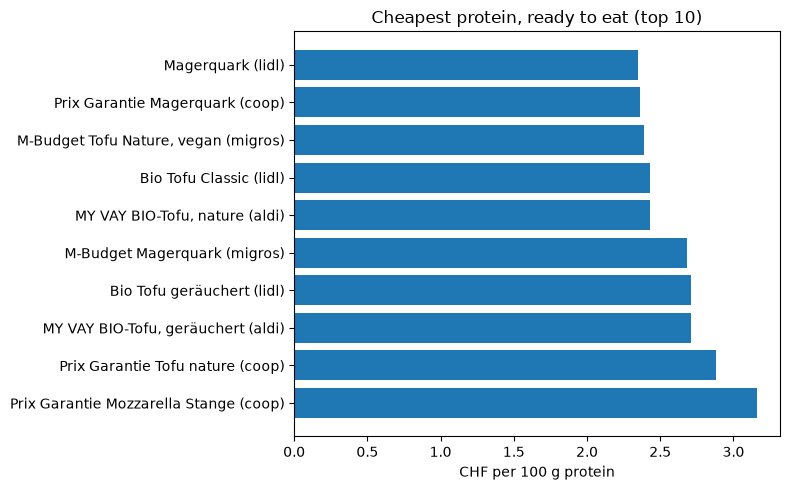

In [5]:
# we chart the result
labels = top10_ready["product"] + " (" + top10_ready["store"] + ")"

plt.figure(figsize=(8, 5))
plt.barh(labels, top10_ready["chf_per_100g_protein"])
plt.gca().invert_yaxis()   # so the cheapest is on top
plt.xlabel("CHF per 100 g protein")
plt.title("Cheapest protein, ready to eat (top 10)")
plt.tight_layout()
plt.show()